In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# Load dataset
df = pd.read_excel("/content/dataset-uci.xlsx")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [6]:
# Display the first five observations
display(df.head())

# Check the dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Inspect column names and data types
df.info()

# Check missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summarise numerical and categorical variables
display(df.describe(include="all").T)

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


Number of rows: 319
Number of columns: 39
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   W

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


**Verify the target variable**

In [7]:
# Display all column names
print(df.columns.tolist())

# Confirm the target column exists
target = "Gallstone Status"

if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' was not found. "
        "Check the exact column name printed above."
    )

# Inspect target values and their frequencies
print("\nTarget class counts:")
print(df[target].value_counts(dropna=False))

print("\nTarget class proportions:")
print(df[target].value_counts(normalize=True, dropna=False) * 100)

['Gallstone Status', 'Age', 'Gender', 'Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']

Target class counts:
Gallstone Status
0    16

In [8]:
# Missing values
missing_summary = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

display(missing_summary[missing_summary > 0])

# Duplicate observations
print("Duplicate rows:", df.duplicated().sum())

# Check data types
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data type": df.dtypes.astype(str).values,
        "Unique values": [
            df[column].nunique(dropna=False)
            for column in df.columns
        ]
    })
)

# Inspect numerical distributions
display(df.select_dtypes(include=np.number).describe().T)

,0


Duplicate rows: 0


,Column,Data type,Unique values
0,Gallstone Status,int64,2
1,Age,int64,56
2,Gender,int64,2
3,Comorbidity,int64,4
4,Coronary Artery Disease (CAD),int64,2
5,Hypothyroidism,int64,2
6,Hyperlipidemia,int64,2
7,Diabetes Mellitus (DM),int64,2
8,Height,int64,46
9,Weight,float64,245


,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.495298,0.500763,0.00,0.000,0.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


In [9]:
# Inspect the most extreme values in selected columns
columns_to_check = [
    "Obesity (%)",
    "Glucose",
    "High Density Lipoprotein (HDL)",
    "Triglyceride",
    "Aspartat Aminotransferaz (AST)",
    "Alanin Aminotransferaz (ALT)",
    "Glomerular Filtration Rate (GFR)"
]

for col in columns_to_check:
    print(f"\n{col}")
    print(df[col].sort_values(ascending=False).head(10).to_list())


Obesity (%)
[1954.0, 125.6, 106.3, 96.63, 95.64, 85.9, 85.8, 83.1, 80.82, 80.8]

Glucose
[575.0, 375.0, 374.0, 325.0, 284.0, 284.0, 247.0, 230.0, 218.0, 215.0]

High Density Lipoprotein (HDL)
[273.0, 93.0, 89.0, 86.0, 82.0, 79.0, 78.0, 77.0, 77.0, 77.0]

Triglyceride
[838.0, 692.0, 679.0, 464.0, 455.0, 391.0, 388.0, 377.0, 375.0, 350.0]

Aspartat Aminotransferaz (AST)
[195.0, 162.0, 149.0, 68.0, 60.0, 49.0, 47.0, 47.0, 45.0, 44.0]

Alanin Aminotransferaz (ALT)
[372.0, 205.0, 104.0, 103.0, 102.0, 96.0, 92.0, 90.0, 79.0, 79.0]

Glomerular Filtration Rate (GFR)
[132.0, 129.4, 128.51, 128.5, 127.22, 126.34, 126.3, 125.9, 125.36, 125.0]


In [10]:
# Compare numerical feature summaries by target class
display(
    df.groupby("Gallstone Status")
      .mean(numeric_only=True)
      .T
      .round(2)
)

Gallstone Status,0,1
Age,47.63,48.51
Gender,0.42,0.57
Comorbidity,0.36,0.31
Coronary Artery Disease (CAD),0.06,0.02
Hypothyroidism,0.04,0.02
Hyperlipidemia,0.00,0.05
Diabetes Mellitus (DM),0.10,0.17
Height,168.23,166.06
Weight,79.81,81.34
Body Mass Index (BMI),28.24,29.53


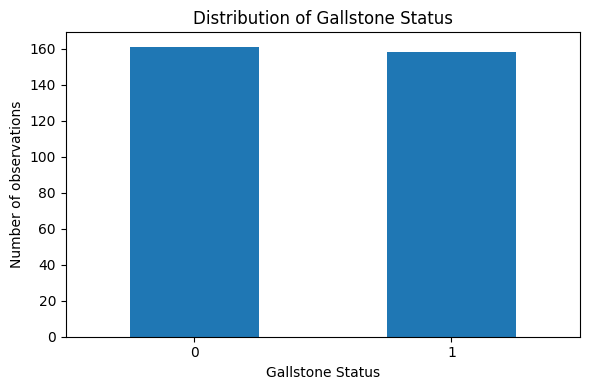

In [11]:
class_counts = df["Gallstone Status"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Distribution of Gallstone Status")
plt.xlabel("Gallstone Status")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# Separate the target from the predictor variables
target = "Gallstone Status"

X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Confirm dimensions and target labels
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

# Verify there are no missing values
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Feature matrix shape: (319, 38)
Target shape: (319,)
Target classes: [np.int64(0), np.int64(1)]
Missing values in X: 0
Missing values in y: 0


In [13]:
# Investigate extreme observations without deleting them

columns_to_check = [
    "Obesity (%)",
    "Glucose",
    "High Density Lipoprotein (HDL)",
    "Triglyceride",
    "Aspartat Aminotransferaz (AST)",
    "Alanin Aminotransferaz (ALT)"
]

for col in columns_to_check:
    print(f"\n{'=' * 60}")
    print(f"Column: {col}")

    extreme_rows = df.nlargest(5, col)[
        ["Gallstone Status", col, "Age", "Gender"]
    ]

    display(extreme_rows)


Column: Obesity (%)


,Gallstone Status,Obesity (%),Age,Gender
239,1,1954.00,51,1
23,0,125.60,57,0
209,1,106.30,64,1
280,1,96.63,53,1
246,1,95.64,48,1



Column: Glucose


,Gallstone Status,Glucose,Age,Gender
40,0,575.0,33,0
312,1,375.0,51,0
20,0,374.0,50,0
310,1,325.0,50,0
242,1,284.0,47,1



Column: High Density Lipoprotein (HDL)


...

,Gallstone Status,Triglyceride,Age,Gender
242,1,838.0,47,1
20,0,692.0,50,0
8,0,679.0,38,0
7,0,464.0,41,0
50,0,455.0,38,0



Column: Aspartat Aminotransferaz (AST)


,Gallstone Status,Aspartat Aminotransferaz (AST),Age,Gender
278,1,195.0,44,0
57,0,162.0,49,0
44,0,149.0,42,0
8,0,68.0,38,0
197,1,60.0,31,0



Column: Alanin Aminotransferaz (ALT)


,Gallstone Status,Alanin Aminotransferaz (ALT),Age,Gender
278,1,372.0,44,0
57,0,205.0,49,0
53,0,104.0,39,0
155,0,103.0,21,0
8,0,102.0,38,0


In [14]:
# Inspect complete records with unusual measurements
suspect_indices = [239, 23, 40, 312, 318, 242, 278]

display(
    df.loc[suspect_indices].T
)

,239,23,40,312,318,242,278
Gallstone Status,1.00,0.000000,0.00,1.00,1.00,1.00,1.00
Age,51.00,57.000000,33.00,51.00,60.00,47.00,44.00
Gender,1.00,0.000000,0.00,0.00,1.00,1.00,0.00
Comorbidity,1.00,0.000000,0.00,1.00,0.00,1.00,0.00
Coronary Artery Disease (CAD),0.00,0.000000,0.00,0.00,0.00,0.00,0.00
Hypothyroidism,0.00,0.000000,0.00,0.00,0.00,0.00,0.00
Hyperlipidemia,0.00,0.000000,0.00,0.00,0.00,0.00,0.00
Diabetes Mellitus (DM),1.00,0.000000,0.00,1.00,0.00,1.00,0.00
Height,150.00,170.000000,172.00,173.00,154.00,173.00,175.00
Weight,65.90,143.500000,75.50,83.80,63.50,87.80,93.10


In [15]:
# Data-quality audit for potentially unusual clinical measurements

audit_columns = [
    "Obesity (%)",
    "Glucose",
    "High Density Lipoprotein (HDL)",
    "Triglyceride",
    "Aspartat Aminotransferaz (AST)",
    "Alanin Aminotransferaz (ALT)"
]

audit_rows = []

for col in audit_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr

    flagged = df[df[col] > upper_fence]

    audit_rows.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Upper IQR fence": upper_fence,
        "Flagged observations": len(flagged),
        "Maximum value": df[col].max()
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df.round(2))

,Variable,Q1,Q3,IQR,Upper IQR fence,Flagged observations,Maximum value
0,Obesity (%),13.90,41.75,27.85,83.52,7,1954.0
1,Glucose,92.00,109.00,17.00,134.50,25,575.0
2,High Density Lipoprotein (HDL),40.00,56.00,16.00,80.00,5,273.0
3,Triglyceride,83.00,172.00,89.00,305.50,20,838.0
4,Aspartat Aminotransferaz (AST),15.00,23.00,8.00,35.00,23,195.0
5,Alanin Aminotransferaz (ALT),14.25,30.00,15.75,53.62,27,372.0


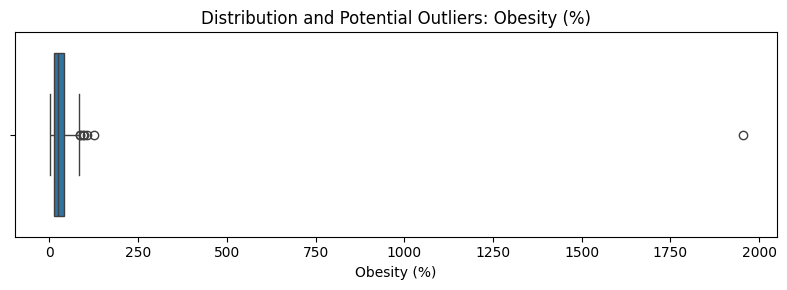

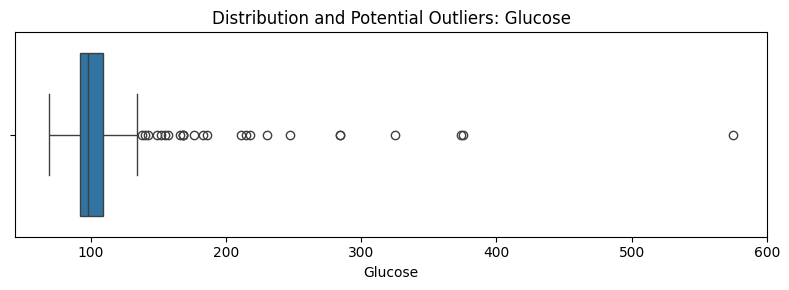

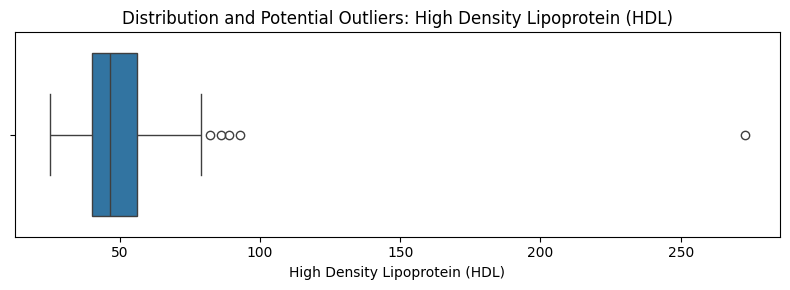

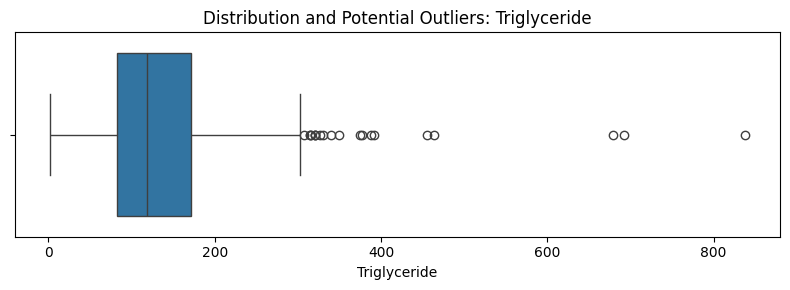

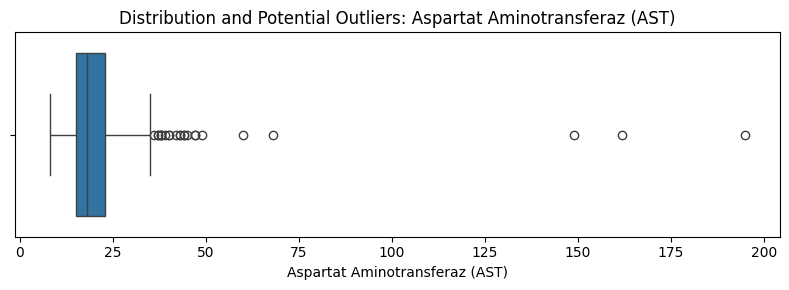

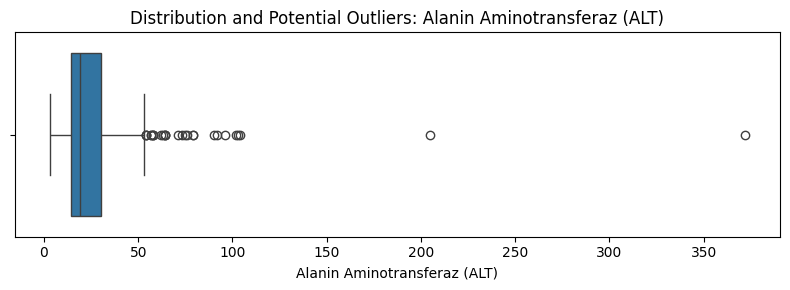

In [16]:
# Boxplots for selected variables to investigate outliers

import matplotlib.pyplot as plt
import seaborn as sns

outlier_columns = [
    "Obesity (%)",
    "Glucose",
    "High Density Lipoprotein (HDL)",
    "Triglyceride",
    "Aspartat Aminotransferaz (AST)",
    "Alanin Aminotransferaz (ALT)"
]

for col in outlier_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Distribution and Potential Outliers: {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [17]:
# Inspect records containing the most extreme values

suspect_records = df[
    (df["Obesity (%)"] > 500) |
    (df["High Density Lipoprotein (HDL)"] > 150)
]

display(suspect_records.T)

,239,318
Gallstone Status,1.00,1.00
Age,51.00,60.00
Gender,1.00,1.00
Comorbidity,1.00,0.00
Coronary Artery Disease (CAD),0.00,0.00
Hypothyroidism,0.00,0.00
Hyperlipidemia,0.00,0.00
Diabetes Mellitus (DM),1.00,0.00
Height,150.00,154.00
Weight,65.90,63.50


In [18]:
# Inspect suspicious observations without changing the dataset

suspect_indices = [239, 318]

columns_to_check = [
    "Gallstone Status",
    "Age",
    "BMI" if "BMI" in df.columns else "Body Mass Index (BMI)",
    "Obesity (%)",
    "Total Cholesterol (TC)",
    "Low Density Lipoprotein (LDL)",
    "High Density Lipoprotein (HDL)",
    "Triglyceride"
]

display(df.loc[suspect_indices, columns_to_check].T)

,239,318
Gallstone Status,1.0,1.0
Age,51.0,60.0
Body Mass Index (BMI),29.3,26.8
Obesity (%),1954.0,21.6
Total Cholesterol (TC),199.0,296.0
Low Density Lipoprotein (LDL),118.0,155.0
High Density Lipoprotein (HDL),57.0,273.0
Triglyceride,138.0,19.0


In [19]:
# Check the suspicious values in the loaded source dataset

print("Row 239 - Obesity (%):",
      df.loc[239, "Obesity (%)"])

print("Row 318 - HDL:",
      df.loc[318, "High Density Lipoprotein (HDL)"])

print("\nDataset dimensions:", df.shape)

Row 239 - Obesity (%): 1954.0
Row 318 - HDL: 273.0

Dataset dimensions: (319, 39)


In [20]:
# Document potential outliers without automatically deleting rows

checks = [
    {
        "Row index": 239,
        "Variable": "Obesity (%)",
        "Observed value": df.loc[239, "Obesity (%)"],
        "Decision": "Flag for source verification"
    },
    {
        "Row index": 318,
        "Variable": "High Density Lipoprotein (HDL)",
        "Observed value": df.loc[318, "High Density Lipoprotein (HDL)"],
        "Decision": "Flag for source verification"
    }
]

quality_report = pd.DataFrame(checks)
display(quality_report)

,Row index,Variable,Observed value,Decision
0,239,Obesity (%),1954.0,Flag for source verification
1,318,High Density Lipoprotein (HDL),273.0,Flag for source verification


In [21]:
# Keep the original dataset unchanged until verification is complete

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

assert df_clean.shape[0] > 300, "Dataset must contain more than 300 rows."

Original dataset shape: (319, 39)
Working dataset shape: (319, 39)
Missing values: 0
Duplicate rows: 0


In [22]:
# Separate the target from the predictor variables

target_column = "Gallstone Status"

X = df_clean.drop(columns=[target_column])
y = df_clean[target_column]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature matrix shape: (319, 38)
Target vector shape: (319,)

Target distribution:
Gallstone Status
0    161
1    158
Name: count, dtype: int64


In [23]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=["Gallstone Status"])
y = df_clean["Gallstone Status"]

# Create a reproducible stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (239, 38)
Testing features: (80, 38)

Training target distribution:
Gallstone Status
0    121
1    118
Name: count, dtype: int64

Testing target distribution:
Gallstone Status
0    40
1    40
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# Candidate models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []
training_proportions = [0.05, 0.15, 0.25]

for proportion in training_proportions:
    X_part, _, y_part, _ = train_test_split(
        X,
        y,
        train_size=proportion,
        stratify=y,
        random_state=42
    )

    # Use a fold count supported by the minority class
    minority_count = y_part.value_counts().min()
    n_splits = min(5, minority_count)

    if n_splits < 2:
        print(f"Skipping {proportion:.0%}: too few samples per class.")
        continue

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    for model_name, model in models.items():
        scores = cross_val_score(
            model,
            X_part,
            y_part,
            cv=cv,
            scoring="accuracy"
        )

        results.append({
            "Training proportion": f"{proportion:.0%}",
            "Training rows": len(X_part),
            "Model": model_name,
            "CV folds": n_splits,
            "Mean CV accuracy": scores.mean(),
            "CV standard deviation": scores.std()
        })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Training proportion,Training rows,Model,CV folds,Mean CV accuracy,CV standard deviation
0,5%,15,Logistic Regression,5,0.533,0.163
1,5%,15,Random Forest,5,0.533,0.267
2,15%,47,Logistic Regression,5,0.722,0.090
3,15%,47,Random Forest,5,0.640,0.126
4,25%,79,Logistic Regression,5,0.618,0.138
5,25%,79,Random Forest,5,0.581,0.092


In [25]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Use a 25% training subset, with the remaining observations held out
X_tune, X_holdout, y_tune, y_holdout = train_test_split(
    X, y,
    train_size=0.25,
    stratify=y,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression pipeline and parameter grid
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=42))
])

lr_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

lr_search.fit(X_tune, y_tune)

print("Logistic Regression best parameters:")
print(lr_search.best_params_)
print("Best CV accuracy:", round(lr_search.best_score_, 3))


# Random Forest and parameter grid
rf = RandomForestClassifier(random_state=42)

rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_search = GridSearchCV(
    estimator=rf,
    param_grid=rf_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

rf_search.fit(X_tune, y_tune)

print("\nRandom Forest best parameters:")
print(rf_search.best_params_)
print("Best CV accuracy:", round(rf_search.best_score_, 3))

Logistic Regression best parameters:
{'model__C': 100, 'model__solver': 'lbfgs'}
Best CV accuracy: 0.658

Random Forest best parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV accuracy: 0.633


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

tuned_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

evaluation_results = []

for name, model in tuned_models.items():
    # Predict on the held-out observations
    y_pred = model.predict(X_holdout)

    evaluation_results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_holdout, y_pred),
        "Precision": precision_score(y_holdout, y_pred, zero_division=0),
        "Recall": recall_score(y_holdout, y_pred, zero_division=0),
        "F1-score": f1_score(y_holdout, y_pred, zero_division=0)
    })

    print(f"\n{name}")
    print(classification_report(y_holdout, y_pred, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_holdout, y_pred))

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

           0       0.83      0.70      0.76       121
           1       0.74      0.85      0.79       119

    accuracy                           0.78       240
   macro avg       0.78      0.78      0.77       240
weighted avg       0.78      0.78      0.77       240

Confusion matrix:
[[ 85  36]
 [ 18 101]]

Random Forest
              precision    recall  f1-score   support

           0       0.77      0.73      0.75       121
           1       0.74      0.78      0.76       119

    accuracy                           0.75       240
   macro avg       0.76      0.75      0.75       240
weighted avg       0.76      0.75      0.75       240

Confusion matrix:
[[88 33]
 [26 93]]


,Model,Test accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.775,0.737,0.849,0.789
1,Random Forest,0.754,0.738,0.782,0.759


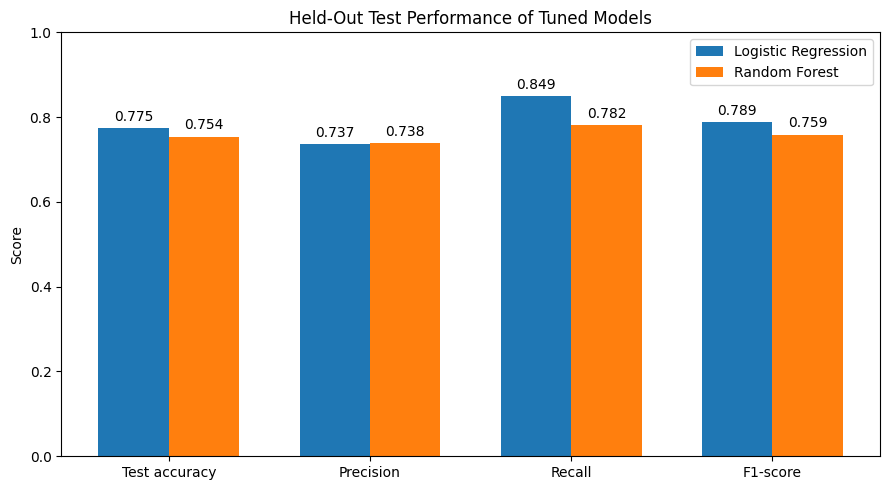

In [27]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Test accuracy", "Precision", "Recall", "F1-score"]

lr_values = [0.775, 0.737, 0.849, 0.789]
rf_values = [0.754, 0.738, 0.782, 0.759]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, lr_values, width, label="Logistic Regression")
bars2 = ax.bar(x + width/2, rf_values, width, label="Random Forest")

ax.set_ylabel("Score")
ax.set_title("Held-Out Test Performance of Tuned Models")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend()

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


Top 10 features: Logistic Regression


,Feature,Mean importance,Standard deviation
35,C-Reactive Protein (CRP),0.0933,0.0138
36,Hemoglobin (HGB),0.0885,0.0167
30,Aspartat Aminotransferaz (AST),0.0883,0.0197
18,Bone Mass (BM),0.0798,0.0218
16,Body Protein Content (Protein) (%),0.0650,0.0188
13,Extracellular Fluid/Total Body Water (ECF/TBW),0.0592,0.0215
15,Lean Mass (LM) (%),0.0448,0.0139
1,Gender,0.0390,0.0178
20,Obesity (%),0.0356,0.0169
37,Vitamin D,0.0348,0.0191


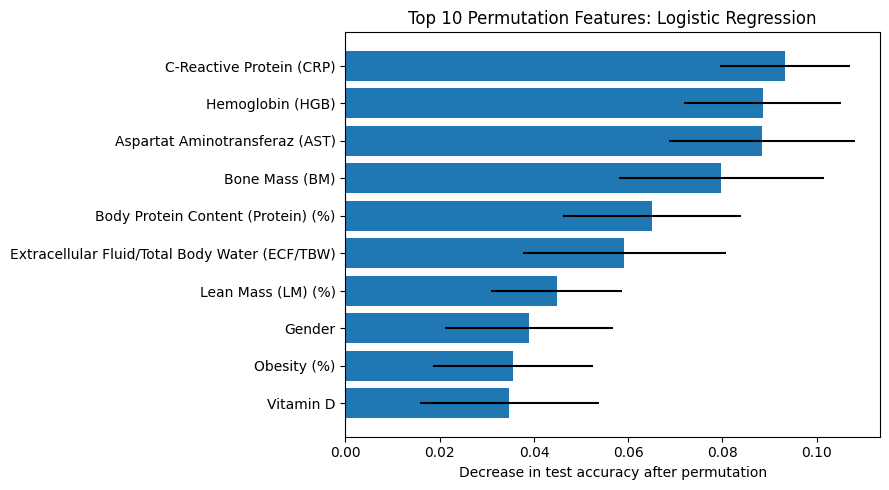


Top 10 features: Random Forest


,Feature,Mean importance,Standard deviation
35,C-Reactive Protein (CRP),0.0860,0.0167
37,Vitamin D,0.0771,0.0265
18,Bone Mass (BM),0.0317,0.0099
13,Extracellular Fluid/Total Body Water (ECF/TBW),0.0258,0.0128
36,Hemoglobin (HGB),0.0158,0.0094
20,Obesity (%),0.0140,0.0084
31,Alanin Aminotransferaz (ALT),0.0121,0.0085
11,Extracellular Water (ECW),0.0087,0.0085
7,Height,0.0065,0.0061
29,Triglyceride,0.0056,0.0078


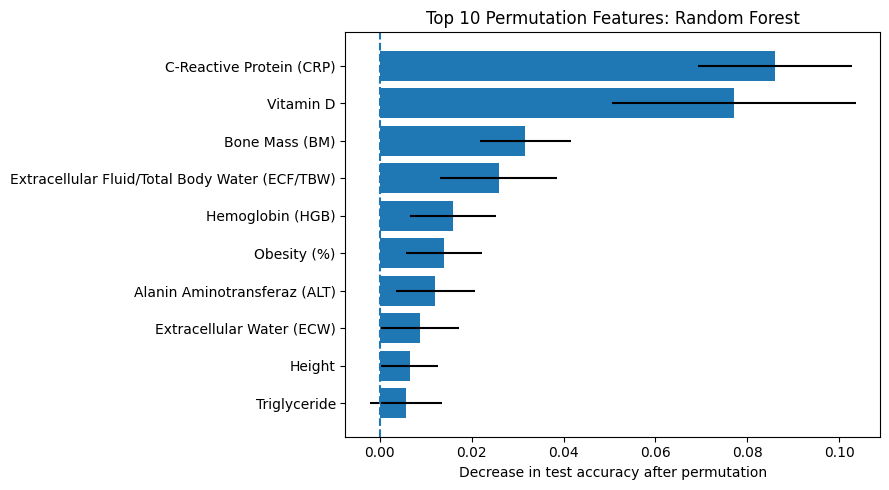

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Analyse feature importance for both tuned models
models_to_analyse = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

importance_results = {}

for model_name, model in models_to_analyse.items():
    result = permutation_importance(
        model,
        X_holdout,
        y_holdout,
        scoring="accuracy",
        n_repeats=20,
        random_state=42,
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        "Feature": X_holdout.columns,
        "Mean importance": result.importances_mean,
        "Standard deviation": result.importances_std
    }).sort_values("Mean importance", ascending=False)

    importance_results[model_name] = importance_df

    print(f"\nTop 10 features: {model_name}")
    display(importance_df.head(10).round(4))

    top_features = importance_df.head(10).sort_values("Mean importance")

    plt.figure(figsize=(9, 5))
    plt.barh(
        top_features["Feature"],
        top_features["Mean importance"],
        xerr=top_features["Standard deviation"]
    )
    plt.axvline(0, linestyle="--")
    plt.xlabel("Decrease in test accuracy after permutation")
    plt.title(f"Top 10 Permutation Features: {model_name}")
    plt.tight_layout()
    plt.show()

In [29]:
from scipy.stats import mannwhitneyu
import pandas as pd

selected_features = [
    "C-Reactive Protein (CRP)",
    "Vitamin D",
    "Hemoglobin (HGB)",
    "Aspartat Aminotransferaz (AST)"
]

statistical_results = []

for feature in selected_features:
    group0 = df_clean.loc[
        df_clean["Gallstone Status"] == 0, feature
    ].dropna()

    group1 = df_clean.loc[
        df_clean["Gallstone Status"] == 1, feature
    ].dropna()

    statistic, p_value = mannwhitneyu(
        group0, group1, alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "Median: status 0": group0.median(),
        "Median: status 1": group1.median(),
        "Mann-Whitney U": statistic,
        "p-value": p_value
    })

stats_df = pd.DataFrame(statistical_results)

# Holm adjustment accounts for testing multiple features
from statsmodels.stats.multitest import multipletests

stats_df["Adjusted p-value (Holm)"] = multipletests(
    stats_df["p-value"], method="holm"
)[1]

display(stats_df.round(4))

,Feature,Median: status 0,Median: status 1,Mann-Whitney U,p-value,Adjusted p-value (Holm)
0,C-Reactive Protein (CRP),0.00,1.29,5312.5,0.0000,0.0000
1,Vitamin D,25.27,17.00,18288.5,0.0000,0.0000
2,Hemoglobin (HGB),14.90,14.20,15535.5,0.0006,0.0006
3,Aspartat Aminotransferaz (AST),20.00,16.50,16968.5,0.0000,0.0000


In [30]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
import pandas as pd

# Use the same 25% training subset used for hyperparameter tuning
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_
}

generalisation_results = []

for name, model in models.items():

    # Accuracy on the data used to fit the final estimator
    train_accuracy = accuracy_score(
        y_tune,
        model.predict(X_tune)
    )

    # Cross-validation accuracy on the tuning subset
    cv_scores = cross_val_score(
        model,
        X_tune,
        y_tune,
        cv=cv,
        scoring="accuracy"
    )

    # Accuracy on the held-out test set
    test_accuracy = accuracy_score(
        y_holdout,
        model.predict(X_holdout)
    )

    generalisation_results.append({
        "Model": name,
        "Training accuracy": train_accuracy,
        "Mean CV accuracy": cv_scores.mean(),
        "CV standard deviation": cv_scores.std(),
        "Held-out test accuracy": test_accuracy,
        "Train-CV gap": train_accuracy - cv_scores.mean()
    })

generalisation_df = pd.DataFrame(generalisation_results)

display(generalisation_df.round(3))

,Model,Training accuracy,Mean CV accuracy,CV standard deviation,Held-out test accuracy,Train-CV gap
0,Logistic Regression,1.0,0.658,0.128,0.775,0.342
1,Random Forest,1.0,0.633,0.063,0.754,0.367
